# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

- **Trạng thái ban đầu.** Bàn là mảng NumPy hai chiều, mặc định 6 hàng × 7 cột. Ô trống là `0`, quân đỏ là `1`, quân vàng là `-1`. Hàng 0 nằm trên cùng. Đỏ đi trước, sau đó hai bên luân phiên. Hàm nhận `player` riêng để biết quân được đặt hoặc góc nhìn cần chấm điểm.
- **Hành động.** Chọn một cột chưa đầy, đánh số từ 0. Ván đã kết thúc không có nước đi hợp lệ.
- **Chuyển trạng thái.** Quân rơi vào ô trống thấp nhất của cột đã chọn. `result` trả về bàn mới để các nhánh tìm kiếm có thể dùng chung bàn gốc.
- **Kết thúc và lợi ích.** Bốn quân cùng màu liên tiếp theo hàng, cột hoặc đường chéo kết thúc ván ngay. Bàn đầy mà chưa ai thắng là hòa. Với người chơi được truyền vào, `utility` trả `1` nếu thắng, `-1` nếu thua, `0` nếu hòa và `None` khi ván còn tiếp diễn. Dùng chung hàm khởi tạo ở cell mẫu và các hàm luật ở Task 2 để mô tả và triển khai cùng một mô hình.

How big is the state space? Give an estimate and explain it.

Với một cột có $h$ quân, trọng lực buộc cả $h$ quân nằm sát đáy. Mỗi vị trí trong chồng quân có thể là đỏ hoặc vàng, nên có tối đa $2^h$ cách xếp cho chiều cao $h$. Cộng các chiều cao từ 0 đến 6 được $1+2+\cdots+2^6=127$ cấu hình cột.

Nếu tạm xem bảy cột độc lập, ta được cận trên $127^7 \approx 5{,}33\times10^{14}$ bàn. Cận này đếm cả những bàn có số quân đỏ và vàng không phù hợp với lượt đi xen kẽ hoặc chỉ có thể xuất hiện nếu vẫn đi tiếp sau khi đã có người thắng. Với các bàn hợp lệ, người đến lượt được suy ra từ số quân vì đỏ luôn đi trước.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

Từ bàn rỗng, mỗi nút có tối đa 7 nước đi và độ sâu không quá $6\times7=42$. Vì vậy số nút mà Minimax có thể phải xét có cận trên
$$
\sum_{d=0}^{42}7^d=\frac{7^{43}-1}{6}\approx3{,}64\times10^{35}.
$$
Cận này đếm cả các nhánh chọn cột đã đầy và các nhánh kéo dài sau khi đã có người thắng, nên số nút thực tế thấp hơn. Cây đếm theo chuỗi nước đi. Hai chuỗi khác nhau dẫn đến cùng một bàn vẫn xuất hiện ở hai nút nếu tìm kiếm không gộp trạng thái.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [ ]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

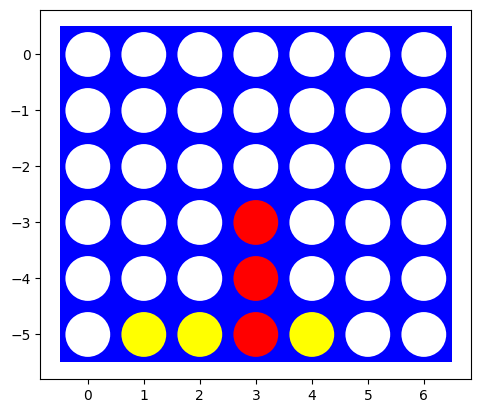

In [ ]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [4]:
from operator import index

from numpy.lib.stride_tricks import sliding_window_view


def _line_windows(state):
    """Return groups of length-four windows in each available direction."""
    rows, cols = state.shape
    if cols >= 4:
        yield sliding_window_view(state, 4, axis=1)
    if rows >= 4:
        yield sliding_window_view(state.T, 4, axis=1)
    if rows >= 4 and cols >= 4:
        squares = sliding_window_view(state, (4, 4))
        yield np.diagonal(squares, axis1=-2, axis2=-1)
        yield np.diagonal(squares[..., ::-1], axis1=-2, axis2=-1)


def _outcome(state):
    """Return the winning color, 0 for a draw, or None while in play."""
    for windows in _line_windows(state):
        first = windows[..., 0]
        wins = (first != 0) & np.all(windows == first[..., None], axis=-1)
        winners = first[wins]
        if winners.size:
            return int(winners[0])

    if np.all(state[0] != 0):
        return 0
    return None


def terminal(state):
    """Check whether either player has won or the board is full."""
    return _outcome(state) is not None


def actions(state):
    """List non-full columns on an ongoing game board."""
    if terminal(state):
        return []
    return np.flatnonzero(state[0] == 0).tolist()


def result(state, player, action):
    """Drop a disc in the given column without modifying the input board."""
    column = index(action)
    if player not in (1, -1):
        raise ValueError("Player must be 1 or -1.")
    if not 0 <= column < state.shape[1] or state[0, column] != 0:
        raise ValueError(f"Column {column} is out of range or full.")
    if terminal(state):
        raise ValueError("The game is already over.")

    next_state = state.copy()
    row = np.flatnonzero(state[:, column] == 0)[-1]
    next_state[row, column] = player
    return next_state


def utility(state, player):
    """Return the final score from player's perspective, or None."""
    if player not in (1, -1):
        raise ValueError("Player must be 1 or -1.")
    outcome = _outcome(state)
    return None if outcome is None else outcome * player


# Kiểm thử luật chơi trên các bàn có kích thước khác nhau.
def board_from_moves(moves, shape=(6, 7)):
    board = empty_board(shape)
    for turn, column in enumerate(moves):
        player = 1 if turn % 2 == 0 else -1
        board = result(board, player, column)
    return board


original = empty_board((3, 5))
assert original.shape == (3, 5)
assert actions(original) == [0, 1, 2, 3, 4]
assert not terminal(original)
assert utility(original, 1) is None and utility(original, -1) is None

first_drop = result(original, 1, 2)
second_drop = result(first_drop, -1, 2)
assert np.count_nonzero(original) == 0
assert first_drop[:, 2].tolist() == [0, 0, 1]
assert second_drop[:, 2].tolist() == [0, -1, 1]

full_column = result(second_drop, 1, 2)
assert actions(full_column) == [0, 1, 3, 4]
for invalid_column in (-1, 2, 5):
    try:
        result(full_column, -1, invalid_column)
    except ValueError:
        continue
    raise AssertionError(f"Invalid column accepted: {invalid_column}")

diagonal_moves = [0, 1, 1, 2, 4, 2, 2, 3, 4, 3, 5, 3, 3]
mirrored_moves = [6 - column for column in diagonal_moves]
draw_moves = [2, 1, 1, 1, 2, 2, 2, 3, 0, 3, 3, 0, 1, 3, 0, 0]
last_win_moves = [2, 2, 3, 2, 3, 1, 0, 0, 2, 1, 3, 1, 0, 3, 0, 1]
cases = [
    ("Thắng ngang", board_from_moves([0, 0, 1, 1, 2, 2, 3]), 1),
    ("Thắng dọc", board_from_moves([0, 1, 0, 1, 2, 1, 2, 1]), -1),
    ("Thắng chéo lên", board_from_moves(diagonal_moves), 1),
    ("Thắng chéo xuống", board_from_moves(mirrored_moves), 1),
    ("Hòa trên bàn 4×4", board_from_moves(draw_moves, (4, 4)), 0),
    ("Thắng bằng nước cuối trên bàn 4×4", board_from_moves(last_win_moves, (4, 4)), -1),
    ("Hòa trên bàn 1×1", board_from_moves([0], (1, 1)), 0),
]
for name, board, expected in cases:
    assert terminal(board) and actions(board) == [], name
    assert utility(board, 1) == expected, name
    assert utility(board, -1) == -expected, name
    print(f"{name} · đạt")

try:
    result(cases[0][1], -1, 4)
except ValueError:
    print("Đi tiếp sau khi có người thắng · bị từ chối")
else:
    raise AssertionError("A move was accepted after the game ended.")

print("Bàn gốc, vị trí quân rơi và cột đầy hoặc ngoài phạm vi · đạt")

print("""
Nhận xét. Các nước đi thử nghiệm tạo được chiến thắng theo bốn hướng và cho điểm đối nhau theo góc nhìn của hai bên. Trên bàn 4×4, ván thắng ở nước cuối vẫn được tính là thắng dù bàn đã kín. Bàn 1×1 kết thúc hòa ngay sau nước đầu vì không đủ chỗ tạo bốn quân liên tiếp.
""")

Thắng ngang · đạt
Thắng dọc · đạt
Thắng chéo lên · đạt
Thắng chéo xuống · đạt
Hòa trên bàn 4×4 · đạt
Thắng bằng nước cuối trên bàn 4×4 · đạt
Hòa trên bàn 1×1 · đạt
Đi tiếp sau khi có người thắng · bị từ chối
Bàn gốc, vị trí quân rơi và cột đầy hoặc ngoài phạm vi · đạt

Nhận xét. Các nước đi thử nghiệm tạo được chiến thắng theo bốn hướng và cho điểm đối nhau theo góc nhìn của hai bên. Trên bàn 4×4, ván thắng ở nước cuối vẫn được tính là thắng dù bàn đã kín. Bàn 1×1 kết thúc hòa ngay sau nước đầu vì không đủ chỗ tạo bốn quân liên tiếp.



Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [5]:
rng = np.random.default_rng()


def random_player(board, player=1):
    """Choose uniformly among the legal columns."""
    legal_columns = actions(board)
    if not legal_columns:
        raise ValueError("No legal move is available.")
    return int(rng.choice(legal_columns))


def play_game(first_agent, second_agent, shape=(6, 7)):
    """Play one game and return 1 for a red win, -1 for yellow, or 0."""
    board = empty_board(shape)
    player = 1
    while True:
        agent = first_agent if player == 1 else second_agent
        board = result(board, player, agent(board, player))
        score = utility(board, 1)
        if score is not None:
            return score
        player = -player

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [6]:
from IPython.display import display

import pandas as pd

game_count = 1000
seed = 30
rng = np.random.default_rng(seed)
totals = {1: 0, -1: 0, 0: 0}
for _ in range(game_count):
    score = play_game(random_player, random_player)
    totals[score] += 1

assert sum(totals.values()) == game_count
labels = {1: "Đỏ thắng (đi trước)", -1: "Vàng thắng (đi sau)", 0: "Hòa"}
summary = pd.DataFrame([
    {
        "Kết quả": labels[score],
        "Số ván": count,
        "Tỷ lệ (%)": round(100 * count / game_count, 1),
    }
    for score, count in totals.items()
])
display(summary)

win_gap = 100 * (totals[1] - totals[-1]) / game_count
print(
    f"Nhận xét. Trong {game_count} ván với seed {seed}, đỏ thắng {totals[1]} ván, "
    f"vàng thắng {totals[-1]} ván và hòa {totals[0]} ván. "
    f"Tỷ lệ thắng của đỏ cao hơn {win_gap:.1f} điểm phần trăm trong mẫu này. "
    "Kết quả phù hợp với kỳ vọng rằng người đi trước có cơ hội tạo chuỗi bốn sớm hơn. "
    "Các tỷ lệ này mô tả hai tác tử chọn cột ngẫu nhiên trong thí nghiệm."
)


,Kết quả,Số ván,Tỷ lệ (%)
0,Đỏ thắng (đi trước),573,57.3
1,Vàng thắng (đi sau),424,42.4
2,Hòa,3,0.3


Nhận xét. Trong 1000 ván với seed 30, đỏ thắng 573 ván, vàng thắng 424 ván và hòa 3 ván. Tỷ lệ thắng của đỏ cao hơn 14.9 điểm phần trăm trong mẫu này. Kết quả phù hợp với kỳ vọng rằng người đi trước có cơ hội tạo chuỗi bốn sớm hơn. Các tỷ lệ này mô tả hai tác tử chọn cột ngẫu nhiên trong thí nghiệm.


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [7]:
# Bàn NumPy vẫn là giao diện chung với môi trường Ngày 1.
# Trong cây tìm kiếm, mỗi màu dùng một số nguyên biểu diễn các ô có quân.
# Mỗi cột có thêm một bit trống để phép dịch bit không nối nhầm qua biên cột.
# Bộ nhớ chỉ chứa kết quả các cây con đã xét xong. Cận Alpha-Beta được ghi
# là exact/lower/upper, cùng độ sâu, để tái sử dụng đúng ở những lượt sau.
from time import perf_counter


class SearchTimeout(TimeoutError):
    pass


def _board_bits(board, player):
    rows, cols = board.shape
    own, opponent = 0, 0
    heights = []
    for col in range(cols):
        heights.append(int(np.count_nonzero(board[:, col])))
        for row in range(rows):
            bit = 1 << (col * (rows + 1) + rows - 1 - row)
            if board[row, col] == player:
                own |= bit
            elif board[row, col] == -player:
                opponent |= bit
    return own, opponent, heights


def _four_masks(rows, cols):
    masks = []
    for row in range(rows):
        for col in range(cols):
            for dr, dc in ((0, 1), (1, 0), (1, 1), (-1, 1)):
                if 0 <= row + 3 * dr < rows and col + 3 * dc < cols:
                    mask = 0
                    for step in range(4):
                        mask |= 1 << ((col + step * dc) * (rows + 1) + row + step * dr)
                    masks.append(mask)
    return masks


class MinimaxAgent:
    """Minimax negamax voi cau hinh co dinh cho moi instance."""

    def __init__(self, pruning=True, ordering=False, memo=True, cutoff=None, time_limit=60):
        if cutoff is not None:
            cutoff = index(cutoff)
            if cutoff < 1:
                raise ValueError("Cutoff must be a positive number of plies.")
        self.pruning = pruning
        self.ordering = ordering
        self.memo = memo
        self.cutoff = cutoff
        self.time_limit = time_limit
        self.table = {}
        self.shape = None
        self.last_search = None

    def _has_won(self, bits):
        for shift in (1, self.stride, self.stride - 1, self.stride + 1):
            pairs = bits & (bits >> shift)
            if pairs & (pairs >> (2 * shift)):
                return True
        return False

    def _search(self, own, opponent, heights, remaining, depth, alpha, beta):
        self.nodes += 1
        if perf_counter() >= self.deadline:
            raise SearchTimeout("The search exceeded its time limit.")
        if self._has_won(opponent):
            return -1, None
        if remaining == 0:
            return 0, None
        if depth == 0:
            return _heuristic_bits(own, opponent, self.masks), None

        key = (own, opponent, depth)
        if self.memo:
            entry = self.table.get(key)
            if entry is not None:
                value, bound, move = entry
                self.cache_hits += 1
                if bound == "exact":
                    return value, move
                # Root needs an optimal move, not just a value bound.
                # Tightening its window can make a bound look like a tied move.
                if self.pruning and self.nodes > 1:
                    if bound == "lower":
                        alpha = max(alpha, value)
                    else:
                        beta = min(beta, value)
                    if alpha >= beta:
                        return value, move

        alpha_start, beta_start = alpha, beta
        best_value, best_move = -2, None
        for col in self.column_order:
            if heights[col] == self.shape[0]:
                continue
            bit = 1 << (col * self.stride + heights[col])
            heights[col] += 1
            try:
                if self.pruning:
                    child_value, _ = self._search(
                        opponent, own | bit, heights, remaining - 1, depth - 1, -beta, -alpha
                    )
                else:
                    child_value, _ = self._search(
                        opponent, own | bit, heights, remaining - 1, depth - 1, -2, 2
                    )
            finally:
                heights[col] -= 1
            value = -child_value
            if value > best_value:
                best_value, best_move = value, col
            if self.pruning:
                alpha = max(alpha, best_value)
                if alpha >= beta:
                    break

        if self.memo:
            bound = "exact"
            if self.pruning:
                if best_value <= alpha_start:
                    bound = "upper"
                elif best_value >= beta_start:
                    bound = "lower"
            self.table[key] = (best_value, bound, best_move)
        return best_value, best_move

    def search(self, board, player=1):
        if player not in (1, -1):
            raise ValueError("Player must be 1 or -1.")
        start = perf_counter()
        self.deadline = start + self.time_limit
        self.nodes, self.cache_hits = 0, 0
        shape = tuple(board.shape)
        if shape != self.shape:
            self.table.clear()
            self.shape = shape
            self.stride = shape[0] + 1
            self.masks = _four_masks(*shape)
            self.column_order = list(range(shape[1]))
            if self.ordering:
                self.column_order.sort(key=lambda col: (abs(2 * col - shape[1] + 1), col))
        value, move, completed = utility(board, player), None, True
        if value is None:
            own, opponent, heights = _board_bits(board, player)
            remaining = board.size - sum(heights)
            depth = remaining if self.cutoff is None else min(self.cutoff, remaining)
            try:
                value, move = self._search(own, opponent, heights, remaining, depth, -2, 2)
            except SearchTimeout:
                value, move, completed = None, None, False
        self.last_search = {
            "move": move,
            "value": value,
            "completed": completed,
            "nodes": self.nodes,
            "cache_hits": self.cache_hits,
            "cache_size": len(self.table),
            "seconds": perf_counter() - start,
        }
        return self.last_search.copy()

    def act(self, board, player=1):
        answer = self.search(board, player)
        if not answer["completed"]:
            raise SearchTimeout("No completed minimax decision within the time limit.")
        if answer["move"] is None:
            raise ValueError("There is no move on a terminal board.")
        return answer["move"]

Agent dùng Negamax để viết chung hai lượt Max/Min. Hàm `act(board, player=1)` trả một cột cho môi trường Ngày 1. Mỗi instance giữ cấu hình, bảng trạng thái, số nút và thời gian của lần tìm kiếm gần nhất. Số nút là số lần vào hàm tìm kiếm, gồm nút lấy được từ cache.

Các phép đo tìm kiếm đầy đủ có giới hạn 60 giây. Khi chạm giới hạn, kết quả mang trạng thái chưa hoàn tất và chưa có quyết định. Hàm `act` báo lỗi khi gặp trạng thái này. Bàn NumPy đầu vào giữ nguyên trong suốt tìm kiếm.

Trong cây tìm kiếm, mỗi màu dùng một số nguyên biểu diễn các ô có quân. Mỗi cột thêm một bit trống để các phép dịch không nối nhầm qua biên. Các hàm môi trường Ngày 1 vẫn nhận và trả bàn NumPy. Cách biểu diễn nội bộ này giảm chi phí tạo mảng và quét bàn ở từng nút.

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [8]:
test_positions = [
    ("Màu 1 thắng ngay", [0, 1, 0, 1, 0, 2], 1, {0}),
    ("Màu -1 thắng ngay", [0, 1, 0, 1, 2, 1, 2], 1, {1}),
    ("Phải chặn cột 1", [0, 1, 0, 1, 2, 1], 0, {1}),
    ("Cuối ván có thể hòa", [2, 1, 1, 1, 2, 2, 2, 3, 0, 3, 3, 0], 0, {0, 1, 3}),
    ("Thế thua bắt buộc", [1, 2, 2, 1, 3, 0, 0, 2, 0, 2, 3, 0], -1, {1, 3}),
]


def measurement_row(name, config, answer):
    return {
        "Bàn": name,
        "Cấu hình": config,
        "Nước đi": answer["move"],
        "Giá trị": answer["value"],
        "Số nút": answer["nodes"],
        "Lượt dùng cache": answer["cache_hits"],
        "Thời gian (s)": answer["seconds"],
        "Hoàn tất": answer["completed"],
    }


position_rows, test_rows = [], []
for name, moves, expected_value, expected_moves in test_positions:
    board = board_from_moves(moves, (4, 4))
    player = (-1) ** len(moves)
    assert not terminal(board)
    position_rows.append({
        "Bàn": name,
        "Chuỗi cột từ bàn rỗng": str(moves),
        "Quân đến lượt": player,
        "Nước tối ưu kỳ vọng": str(sorted(expected_moves)),
        "Giá trị kỳ vọng": expected_value,
    })
    for pruning, label in [(False, "Minimax"), (True, "Alpha-Beta")]:
        agent = MinimaxAgent(pruning=pruning, memo=False)
        saved_board = board.copy()
        answer = agent.search(board, player)
        assert answer["completed"]
        assert answer["value"] == expected_value
        assert answer["move"] in expected_moves
        assert np.array_equal(board, saved_board)
        test_rows.append(measurement_row(name, label, answer))

display(pd.DataFrame(position_rows))
test_table = pd.DataFrame(test_rows)
display(test_table.round({"Thời gian (s)": 6}))

# Hồi quy cho việc chọn nước khi nút gốc đã có một cận dưới trong cache.
cache_board = board_from_moves([1, 1, 2, 1, 3, 0, 3, 1, 2, 2, 3], (4, 4))
cache_agent = MinimaxAgent(ordering=True)
cache_agent.search(empty_board((4, 4)))
own, opponent, heights = _board_bits(cache_board, -1)
cache_key = (own, opponent, cache_board.size - sum(heights))
cache_agent.table[cache_key] = (1, "lower", 3)
cache_answer = cache_agent.search(cache_board, -1)
assert cache_answer["value"] == 1 and cache_answer["move"] == 3
print("Cache chứa cận dưới ở nút gốc · vẫn chọn đúng cột thắng 3")

,Bàn,Chuỗi cột từ bàn rỗng,Quân đến lượt,Nước tối ưu kỳ vọng,Giá trị kỳ vọng
0,Màu 1 thắng ngay,"[0, 1, 0, 1, 0, 2]",1,[0],1
1,Màu -1 thắng ngay,"[0, 1, 0, 1, 2, 1, 2]",-1,[1],1
2,Phải chặn cột 1,"[0, 1, 0, 1, 2, 1]",1,[1],0
3,Cuối ván có thể hòa,"[2, 1, 1, 1, 2, 2, 2, 3, 0, 3, 3, 0]",1,"[0, 1, 3]",0
4,Thế thua bắt buộc,"[1, 2, 2, 1, 3, 0, 0, 2, 0, 2, 3, 0]",1,"[1, 3]",-1


,Bàn,Cấu hình,Nước đi,Giá trị,Số nút,Lượt dùng cache,Thời gian (s),Hoàn tất
0,Màu 1 thắng ngay,Minimax,0,1,18099,0,0.022258,True
1,Màu 1 thắng ngay,Alpha-Beta,0,1,162,0,0.000465,True
2,Màu -1 thắng ngay,Minimax,1,1,5158,0,0.006482,True
3,Màu -1 thắng ngay,Alpha-Beta,1,1,145,0,0.000425,True
4,Phải chặn cột 1,Minimax,1,0,18178,0,0.022129,True
5,Phải chặn cột 1,Alpha-Beta,1,0,300,0,0.000634,True
6,Cuối ván có thể hòa,Minimax,0,0,35,0,0.000189,True
7,Cuối ván có thể hòa,Alpha-Beta,0,0,25,0,0.000178,True
8,Thế thua bắt buộc,Minimax,1,-1,16,0,0.000175,True
9,Thế thua bắt buộc,Alpha-Beta,1,-1,14,0,0.000168,True


Cache chứa cận dưới ở nút gốc · vẫn chọn đúng cột thắng 3


Hai thuật toán đạt cùng giá trị kỳ vọng trên cả năm bàn. Ở hai bàn đầu, agent chọn ngay cột thắng cho đúng màu đang đi. Bàn thứ ba chỉ có cột 1 giữ được hòa, các nước còn lại dẫn đến thua khi đối thủ chơi tối ưu. Bàn thứ tư có nhiều nước cùng giữ hòa. Ở thế thua bắt buộc, agent vẫn trả một nước hợp lệ với giá trị -1.

Alpha-Beta dùng cùng utility và không giới hạn độ sâu nên giữ giá trị tối ưu của Minimax. Thuật toán có thể trả một nước đồng hạng khác khi thay đổi thứ tự duyệt. Các phép đo ở bảng này đều tắt cache để đối chiếu riêng tác động cắt tỉa.

Kiểm tra hồi quy bổ sung dùng một bàn mà cache đã chứa cận dưới ở nút gốc. Agent vẫn phải chọn cột 3 để thắng. Ở nút gốc, một kết quả cache chính xác có thể trả ngay nước đi; một cận chưa chính xác chỉ được tái sử dụng trong các cây con.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [9]:
# Mỗi bàn rỗng được đo bằng một agent mới, không dùng cache từ bàn trước.
size_rows = []
for shape in [(4, 4), (4, 5), (5, 5), (6, 7)]:
    board = empty_board(shape)
    agent = MinimaxAgent(pruning=True, memo=True, time_limit=60)
    answer = agent.search(board)
    row = measurement_row(f"{shape[0]}×{shape[1]}", "Alpha-Beta + cache", answer)
    row["Ô trống"] = board.size
    row["Giới hạn (s)"] = agent.time_limit
    row["Trạng thái"] = "Đã giải đầy đủ" if answer["completed"] else "Chạm giới hạn 60 s"
    size_rows.append(row)
    print(f"{shape} · {row['Trạng thái']} · {answer['seconds']:.3f} s", flush=True)

size_table = pd.DataFrame(size_rows)
display(size_table.round({"Thời gian (s)": 3}))

(4, 4) · Đã giải đầy đủ · 0.022 s


(4, 5) · Đã giải đầy đủ · 1.098 s


(5, 5) · Đã giải đầy đủ · 18.121 s


(6, 7) · Chạm giới hạn 60 s · 60.000 s


,Bàn,Cấu hình,Nước đi,Giá trị,Số nút,Lượt dùng cache,Thời gian (s),Hoàn tất,Ô trống,Giới hạn (s),Trạng thái
0,4×4,Alpha-Beta + cache,0.0,0.0,13554,2480,0.022,True,16,60,Đã giải đầy đủ
1,4×5,Alpha-Beta + cache,1.0,0.0,623460,173077,1.098,True,20,60,Đã giải đầy đủ
2,5×5,Alpha-Beta + cache,0.0,0.0,9993865,2840369,18.121,True,25,60,Đã giải đầy đủ
3,6×7,Alpha-Beta + cache,NaN,NaN,28220082,6950801,60.000,False,42,60,Chạm giới hạn 60 s


- Bàn 4×4 có 16 ô trống. Đã giải đầy đủ sau 0,022 giây, với 13.554 lượt xét nút.
- Bàn 4×5 có 20 ô trống. Đã giải đầy đủ sau 1,098 giây, với 623.460 lượt xét nút.
- Bàn 5×5 có 25 ô trống. Đã giải đầy đủ sau 18,121 giây, với 9.993.865 lượt xét nút.
- Bàn 6×7 có 42 ô trống. Agent xét hàng chục triệu nút vẫn chưa tìm xong trong giới hạn 60 giây.

Các số đo đều dùng Alpha-Beta có cache, thứ tự cột tự nhiên và bộ nhớ trống lúc bắt đầu. Những hàng chưa hoàn tất không có nước đi hay giá trị Minimax đầy đủ. Số nút xét được trước giới hạn thời gian phụ thuộc tốc độ máy và tải hệ thống nên thay đổi giữa các lần chạy.

Thêm cột làm tăng số hành động tại mỗi nút, còn thêm hàng tăng số lượt tối đa trước khi bàn đầy. Bàn 6×7 có thể sâu tới 42 lượt và tối đa 7 nhánh mỗi lượt. Alpha-Beta và cache giảm công việc nhưng vẫn phải xử lý một không gian rất lớn. Số liệu trên mô tả thời gian của cách triển khai này và máy chạy thí nghiệm. Trong cùng giới hạn, một bàn lớn hơn có thể được cắt tỉa thuận lợi hơn một bàn nhỏ, nên thời gian không nhất thiết tăng đều theo từng hàng.

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [10]:
# Cột giữa được xét trước, cùng khoảng cách thì ưu tiên chỉ số nhỏ hơn.
# Mỗi cấu hình bắt đầu với cache trống và đều tìm tới cuối ván.
ordering_positions = [(name, moves) for name, moves, _, _ in test_positions]
ordering_positions.append(("Bàn rỗng 4×4", []))
ordering_rows = []
for name, moves in ordering_positions:
    board = board_from_moves(moves, (4, 4))
    player = (-1) ** len(moves)
    answers = []
    for ordered, label in [(False, "Thứ tự cột 0→3"), (True, "Ưu tiên giữa")]:
        agent = MinimaxAgent(ordering=ordered, memo=True)
        answer = agent.search(board, player)
        assert answer["completed"]
        answers.append(answer)
        ordering_rows.append(measurement_row(name, label, answer))
    assert answers[0]["value"] == answers[1]["value"]

ordering_table = pd.DataFrame(ordering_rows)
display(ordering_table.round({"Thời gian (s)": 6}))

,Bàn,Cấu hình,Nước đi,Giá trị,Số nút,Lượt dùng cache,Thời gian (s),Hoàn tất
0,Màu 1 thắng ngay,Thứ tự cột 0→3,0,1,99,6,0.000427,True
1,Màu 1 thắng ngay,Ưu tiên giữa,0,1,292,31,0.000647,True
2,Màu -1 thắng ngay,Thứ tự cột 0→3,1,1,99,8,0.000309,True
3,Màu -1 thắng ngay,Ưu tiên giữa,1,1,73,6,0.000296,True
4,Phải chặn cột 1,Thứ tự cột 0→3,1,0,168,13,0.000404,True
5,Phải chặn cột 1,Ưu tiên giữa,1,0,190,16,0.000456,True
6,Cuối ván có thể hòa,Thứ tự cột 0→3,0,0,24,1,0.000182,True
7,Cuối ván có thể hòa,Ưu tiên giữa,1,0,19,1,0.000200,True
8,Thế thua bắt buộc,Thứ tự cột 0→3,1,-1,14,0,0.000165,True
9,Thế thua bắt buộc,Ưu tiên giữa,1,-1,14,0,0.000170,True


Trên bàn rỗng 4×4, thứ tự cột tự nhiên xét 13.554 nút trong 0,027 giây. Ưu tiên giữa xét 27.427 nút trong 0,044 giây. Hai cấu hình cho cùng giá trị Minimax.

Xét nước mạnh sớm giúp siết alpha hoặc beta sớm và có thể bỏ nhiều nhánh hơn. Quy tắc ưu tiên giữa vẫn chỉ là dự đoán thứ tự tốt. Trên một bàn cụ thể, số nút có thể tăng. Thời gian rất ngắn còn chịu nhiễu của máy, nên cần đọc cùng số nút. Cả hai cấu hình trong bảng đều có cache và bắt đầu từ bộ nhớ trống.

Trong phép đo bàn rỗng này, ưu tiên giữa làm số nút tăng từ 13.554 lên 27.427. Thứ tự tự nhiên hiệu quả hơn ở trường hợp đó. Các bàn khác trong bảng cho phép đối chiếu tác động của cùng quy tắc khi thế cờ thay đổi.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [11]:
# Các phép đo dưới đây đều bắt đầu từ bàn rỗng và cache trống.
first_move_rows = []
first_move_configs = [
    ("Minimax", dict(pruning=False, memo=False)),
    ("Alpha-Beta", dict(pruning=True, memo=False)),
    ("Alpha-Beta + cache", dict(pruning=True, memo=True)),
]
for label, config in first_move_configs:
    agent = MinimaxAgent(ordering=True, time_limit=60, **config)
    answer = agent.search(empty_board((4, 4)))
    if answer["completed"]:
        assert answer["value"] == 0
    first_move_rows.append(measurement_row("Bàn rỗng 4×4", label, answer))
    print(f"{label} · hoàn tất={answer['completed']} · {answer['seconds']:.3f} s", flush=True)

first_move_table = pd.DataFrame(first_move_rows)
display(first_move_table.round({"Thời gian (s)": 6}))

Minimax · hoàn tất=False · 60.000 s


Alpha-Beta · hoàn tất=True · 0.212 s


Alpha-Beta + cache · hoàn tất=True · 0.045 s


,Bàn,Cấu hình,Nước đi,Giá trị,Số nút,Lượt dùng cache,Thời gian (s),Hoàn tất
0,Bàn rỗng 4×4,Minimax,NaN,NaN,48350595,0,60.000021,False
1,Bàn rỗng 4×4,Alpha-Beta,1.0,0.0,155968,0,0.211992,True
2,Bàn rỗng 4×4,Alpha-Beta + cache,1.0,0.0,27427,5982,0.044513,True


- Minimax xét hàng chục triệu nút vẫn chưa tìm xong nước đầu trên bàn 4×4 trong giới hạn 60 giây.
- Alpha-Beta hoàn tất sau khoảng 0,212 giây, với 155.968 lượt xét nút.
- Alpha-Beta có cache hoàn tất sau khoảng 0,045 giây, với 27.427 lượt xét nút.

Các cấu hình cùng ưu tiên cột giữa và bắt đầu từ bàn rỗng 4×4. Mọi kết quả đã hoàn tất đều có giá trị 0, tức có thể giữ hòa nếu hai bên tiếp tục chơi tối ưu. Bảng cho thấy riêng tác động của cắt tỉa và lưu trạng thái đã xét. Bảng cache ghi đúng loại cận Alpha-Beta để không coi kết quả cắt tỉa là giá trị chính xác.

Để giảm thời gian chọn nước đầu, có thể lưu kết quả mở đầu đã giải hoặc tái sử dụng cache. Khi tăng lên bàn lớn, có thể dùng heuristic và cutoff ở Task 4 để giới hạn độ sâu. Kết quả khi dùng cutoff cần được đánh giá về chất lượng nước đi.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [12]:
# Dùng lại play_game và random_player của Ngày 1, trên bàn 4×4.
# Mỗi vai dùng một instance riêng. Cache được giữ giữa các lượt và các ván.
# Vì vậy thời gian bên dưới có cả lượt đầu cache trống và các lượt đã có cache.
match_rows = []
for side in (1, -1):
    rng = np.random.default_rng(300 + side)
    agent = MinimaxAgent(pruning=True, ordering=True, memo=True, time_limit=60)
    elapsed_moves, nodes_per_move, hits_per_move = [], [], []

    def measured_agent(board, player):
        move = agent.act(board, player)
        elapsed_moves.append(agent.last_search["seconds"])
        nodes_per_move.append(agent.last_search["nodes"])
        hits_per_move.append(agent.last_search["cache_hits"])
        return move

    totals = {1: 0, -1: 0, 0: 0}
    for _ in range(100):
        if side == 1:
            outcome = play_game(measured_agent, random_player, shape=(4, 4))
        else:
            outcome = play_game(random_player, measured_agent, shape=(4, 4))
        totals[outcome] += 1

    assert sum(totals.values()) == 100 and totals[-side] == 0
    match_rows.append({
        "Quân Minimax/Alpha-Beta": side,
        "Số ván": 100,
        "Thắng": totals[side],
        "Hòa": totals[0],
        "Thua": totals[-side],
        "TB/nước (ms)": 1000 * np.mean(elapsed_moves),
        "TB số nút/nước": np.mean(nodes_per_move),
        "Lượt dùng cache": sum(hits_per_move),
    })

match_table = pd.DataFrame(match_rows)
display(match_table.round({"TB/nước (ms)": 3, "TB số nút/nước": 2}))

,Quân Minimax/Alpha-Beta,Số ván,Thắng,Hòa,Thua,TB/nước (ms),TB số nút/nước,Lượt dùng cache
0,1,100,42,58,0,0.216,56.19,12775
1,-1,100,84,16,0,0.267,85.30,16370


- Cầm quân 1, agent thắng 42, hòa 58, thua 0 trên 100 ván. Trung bình 0,216 ms mỗi nước.
- Cầm quân -1, agent thắng 84, hòa 16, thua 0 trên 100 ván. Trung bình 0,267 ms mỗi nước.

Agent dùng Minimax với Alpha-Beta, tìm tới cuối ván trên bàn 4×4. Kết quả không có ván thua phù hợp với giá trị hòa của bàn rỗng khi chơi tối ưu. Các ván thắng xuất hiện khi Random chọn nước yếu. Mỗi vai có seed cố định và một instance riêng. Cache được giữ giữa các lượt và các ván, nên thời gian trung bình gồm cả các lượt đã có kết quả trong cache và không thay cho phép đo nước đầu với cache trống.

Hai vai dùng seed khác nhau và gặp các thế cờ khác nhau do Random tạo ra. Vì vậy, chênh lệch 42 và 84 ván thắng chưa cho phép tách riêng tác động của việc đi trước hay đi sau; cả hai cấu hình đều không thua trong mẫu đã chạy.

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [13]:
def _heuristic_bits(own, opponent, masks):
    weights = (0, 1, 4, 16, 0)
    raw = 0
    for mask in masks:
        own_count = (own & mask).bit_count()
        opponent_count = (opponent & mask).bit_count()
        if opponent_count == 0:
            raw += weights[own_count]
        if own_count == 0:
            raw -= weights[opponent_count]
    return raw / (abs(raw) + 1)


def heuristic(board, player=1):
    final_value = utility(board, player)
    if final_value is not None:
        return final_value
    own, opponent, _ = _board_bits(board, player)
    return _heuristic_bits(own, opponent, _four_masks(*board.shape))


heuristic_rows = []
for name, moves, _, _ in test_positions:
    board = board_from_moves(moves, (4, 4))
    red_value, yellow_value = heuristic(board, 1), heuristic(board, -1)
    assert -1 < red_value < 1 and red_value == -yellow_value
    heuristic_rows.append({"Bàn": name, "Heuristic quân 1": red_value, "Heuristic quân -1": yellow_value})

won = board_from_moves([0, 1, 0, 1, 0, 2, 0], (4, 4))
assert heuristic(won, 1) == 1 and heuristic(won, -1) == -1
display(pd.DataFrame(heuristic_rows).round(4))

,Bàn,Heuristic quân 1,Heuristic quân -1
0,Màu 1 thắng ngay,0.9231,-0.9231
1,Màu -1 thắng ngay,-0.9000,0.9000
2,Phải chặn cột 1,-0.9286,0.9286
3,Cuối ván có thể hòa,0.5000,-0.5000
4,Thế thua bắt buộc,-0.9412,0.9412


Heuristic xét mọi cửa sổ bốn ô theo hàng, cột và hai đường chéo. Cửa sổ có cả hai màu không còn tạo được chuỗi thắng cho riêng một bên nên có điểm 0. Cửa sổ chỉ chứa một màu có trọng số 1, 4, 16 khi có một, hai, ba quân. Tổng điểm của người đang xét trừ tổng điểm của đối thủ được chuẩn hóa bằng `raw / (abs(raw) + 1)`.

Ở bàn chưa kết thúc, giá trị luôn thuộc (-1, 1). Bàn kết thúc dùng utility thật ±1 hoặc 0. Heuristic có tính đối xứng khi đổi màu. Phép đếm cửa sổ chưa xét đầy đủ khả năng tiếp cận ô trống do trọng lực nên giá trị này là ước lượng.

Phép chuẩn hóa này tiến gần ±1 khi độ lớn của raw tăng, nên các thế có raw lớn có thể nhận những giá trị heuristic khá gần nhau. Đây là một hạn chế khi dùng điểm ước lượng để phân biệt chất lượng các thế cờ.

### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [14]:
cutoff_positions = [(name, moves) for name, moves, _, _ in test_positions]
cutoff_positions.append(("Cần nhìn xa hơn", [3, 0, 0, 2, 3, 1, 0]))
cutoff_rows = []
reference_agent = MinimaxAgent(ordering=True, memo=True)
for name, moves in cutoff_positions:
    board = board_from_moves(moves, (4, 4))
    player = (-1) ** len(moves)
    exact = reference_agent.search(board, player)
    assert exact["completed"]
    for depth in (2, 4, 6):
        agent = MinimaxAgent(ordering=True, memo=True, cutoff=depth)
        answer = agent.search(board, player)
        assert answer["completed"] and answer["move"] in actions(board)
        child = result(board, player, answer["move"])
        chosen = reference_agent.search(child, -player)
        assert chosen["completed"]
        chosen_value = -chosen["value"]
        cutoff_rows.append({
            "Bàn": name,
            "Cutoff": depth,
            "Nước đi": answer["move"],
            "Ước lượng": answer["value"],
            "Giá trị đầy đủ của nước chọn": chosen_value,
            "Chọn nước tối ưu": chosen_value == exact["value"],
            "Số nút": answer["nodes"],
            "Thời gian (s)": answer["seconds"],
        })

cutoff_table = pd.DataFrame(cutoff_rows)
display(cutoff_table.round({"Ước lượng": 4, "Thời gian (s)": 6}))

,Bàn,Cutoff,Nước đi,Ước lượng,Giá trị đầy đủ của nước chọn,Chọn nước tối ưu,Số nút,Thời gian (s)
0,Màu 1 thắng ngay,2,0,1.0000,1,True,11,0.000249
1,Màu 1 thắng ngay,4,0,1.0000,1,True,68,0.000315
2,Màu 1 thắng ngay,6,0,1.0000,1,True,182,0.000540
3,Màu -1 thắng ngay,2,1,1.0000,1,True,8,0.000181
4,Màu -1 thắng ngay,4,1,1.0000,1,True,23,0.000205
5,Màu -1 thắng ngay,6,1,1.0000,1,True,48,0.000246
6,Phải chặn cột 1,2,1,-0.7500,0,True,11,0.000185
7,Phải chặn cột 1,4,1,-0.6667,0,True,33,0.000233
8,Phải chặn cột 1,6,1,-0.9167,0,True,129,0.000446
9,Cuối ván có thể hòa,2,1,0.0000,0,True,8,0.000175


- Cutoff 2 chọn nước tối ưu ở 5/6 bàn. Tổng số nút của sáu lần tìm kiếm là 60.
- Cutoff 4 chọn nước tối ưu ở 5/6 bàn. Tổng số nút của sáu lần tìm kiếm là 294.
- Cutoff 6 chọn nước tối ưu ở 6/6 bàn. Tổng số nút của sáu lần tìm kiếm là 925.

Trên bàn **Cần nhìn xa hơn**, cutoff 2 và 4 đều chọn cột 1, có giá trị đầy đủ -1 (thua khi đối thủ chơi tối ưu). Cutoff 6 chọn cột 3, có giá trị đầy đủ 0 (giữ hòa).

Bàn **Cần nhìn xa hơn** được tạo từ chuỗi cột `[3, 0, 0, 2, 3, 1, 0]`, quân -1 đến lượt. Trong bảng, cột ước lượng là kết quả heuristic của tìm kiếm giới hạn. Cột giá trị đầy đủ của nước chọn được tính bằng agent tìm tới cuối ván, dùng để kiểm tra chất lượng quyết định.

Độ sâu được tính theo số nước tiếp theo, gồm cả nước của người đang xét. Kiểm tra thắng, thua, hòa diễn ra trước khi xét cutoff. Độ sâu lớn hơn thường cần nhiều nút và thời gian hơn, đồng thời có cơ hội nhìn được đe dọa xa hơn. Chất lượng vẫn phụ thuộc heuristic và thế cờ. Mỗi cấu hình bắt đầu bằng cache trống, và khóa cache có độ sâu để các lần tìm kiếm không dùng nhầm kết quả khác cutoff.

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [15]:
# Dùng lại năm chuỗi nước Ngày 2 trên bàn chuẩn 6×7, thêm một thế thắng chéo.
standard_positions = []
for name, moves, _, _ in test_positions:
    if name == "Cuối ván có thể hòa":
        name = "Chuỗi từ bàn hòa 4×4"
    elif name == "Thế thua bắt buộc":
        name = "Chuỗi từ thế thua 4×4"
    standard_positions.append((name, moves))
standard_positions.append(("Có thể thắng chéo", [0, 1, 1, 2, 4, 2, 2, 3, 4, 3, 5, 3]))
tactical_moves = {
    "Màu 1 thắng ngay": {0},
    "Màu -1 thắng ngay": {1},
    "Phải chặn cột 1": {1},
    "Có thể thắng chéo": {3},
}

standard_rows = []
for name, moves in standard_positions:
    board = board_from_moves(moves, (6, 7))
    player = (-1) ** len(moves)
    assert not terminal(board)
    for depth in (2, 4, 6):
        saved_board = board.copy()
        agent = MinimaxAgent(ordering=True, memo=True, cutoff=depth, time_limit=60)
        answer = agent.search(board, player)
        assert answer["completed"] and answer["move"] in actions(board)
        assert np.array_equal(board, saved_board)
        if name in tactical_moves:
            assert answer["move"] in tactical_moves[name], (name, depth, answer)
        standard_rows.append({
            "Bàn 6×7": name,
            "Quân": player,
            "Cutoff": depth,
            "Cột": answer["move"],
            "Ước lượng": answer["value"],
            "Số nút": answer["nodes"],
            "Thời gian (s)": answer["seconds"],
        })
standard_table = pd.DataFrame(standard_rows)
display(standard_table.round({"Ước lượng": 4, "Thời gian (s)": 6}))

,Bàn 6×7,Quân,Cutoff,Cột,Ước lượng,Số nút,Thời gian (s)
0,Màu 1 thắng ngay,1,2,0,1.0000,34,0.000605
1,Màu 1 thắng ngay,1,4,0,1.0000,666,0.006074
2,Màu 1 thắng ngay,1,6,0,1.0000,7805,0.063440
3,Màu -1 thắng ngay,-1,2,1,1.0000,27,0.000512
4,Màu -1 thắng ngay,-1,4,1,1.0000,388,0.003873
5,Màu -1 thắng ngay,-1,6,1,1.0000,3488,0.030162
6,Phải chặn cột 1,1,2,1,-0.8750,33,0.000564
7,Phải chặn cột 1,1,4,1,-0.9091,436,0.004337
8,Phải chặn cột 1,1,6,1,-0.9231,4247,0.036291
9,Chuỗi từ bàn hòa 4×4,1,2,1,0.8571,39,0.000657


Các cutoff 2, 4, 6 đều tìm đúng cột thắng ngay cho hai màu, cột chặn bắt buộc và nước thắng chéo trên các thế cờ thử nghiệm. Những phép tìm kiếm này bắt đầu với cache trống và giới hạn 60 giây. Bảng ghi thời gian cùng số nút để đối chiếu chi phí.

Năm chuỗi nước của Ngày 2 được đặt lại trên bàn 6×7. Với hai chuỗi từng tạo thế hòa hoặc thế thua trên 4×4, việc thêm hàng và cột thay đổi các nước còn lại và khả năng tạo chuỗi bốn. Vì vậy bảng dùng tên mô tả nguồn chuỗi, và không gán lại giá trị Minimax đầy đủ của bàn 4×4 cho bàn 6×7. Các điểm trong cột ước lượng là kết quả tìm kiếm có cutoff.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [16]:
# Mỗi lần đo dùng bàn rỗng, cùng 6 hàng và một instance với cache trống.
heuristic_size_rows = []
for columns in (4, 5, 6, 7):
    for depth in (2, 4, 6):
        agent = MinimaxAgent(ordering=True, memo=True, cutoff=depth, time_limit=60)
        answer = agent.search(empty_board((6, columns)), player=1)
        assert answer["completed"]
        heuristic_size_rows.append({
            "Kích thước": f"6×{columns}",
            "Cutoff": depth,
            "Cột": answer["move"],
            "Số nút": answer["nodes"],
            "Lượt dùng cache": answer["cache_hits"],
            "Thời gian (s)": answer["seconds"],
        })
heuristic_size_table = pd.DataFrame(heuristic_size_rows)
display(heuristic_size_table.round({"Thời gian (s)": 6}))

,Kích thước,Cutoff,Cột,Số nút,Lượt dùng cache,Thời gian (s)
0,6×4,2,0,19,0,0.000353
1,6×4,4,0,169,7,0.000832
2,6×4,6,0,1154,56,0.004269
3,6×5,2,0,26,0,0.000408
4,6×5,4,1,231,10,0.001425
5,6×5,6,1,1141,67,0.005998
6,6×6,2,1,27,0,0.000539
7,6×6,4,2,232,12,0.001830
8,6×6,6,1,1928,146,0.013265
9,6×7,2,3,24,0,0.000503


- Cutoff 2 trên bàn rỗng 6×7 xét 24 nút, làm mốc so sánh thời gian.
- Cutoff 4 trên bàn rỗng 6×7 xét 174 nút, mất thời gian khoảng 3,3 lần cutoff 2.
- Cutoff 6 trên bàn rỗng 6×7 xét 952 nút, mất thời gian khoảng 14,3 lần cutoff 2 và 4,3 lần cutoff 4.

Mỗi hàng dùng một instance mới, cùng thứ tự ưu tiên giữa và cache trống. Độ sâu lớn hơn có thể mở nhiều tầng hơn và cần thêm thời gian. Thêm cột tăng số lựa chọn, nhưng cắt tỉa, thứ tự duyệt và các trạng thái trùng có thể làm số nút và thời gian giữa hai kích thước không tăng đều. Các số đo nhỏ còn chịu nhiễu của máy chạy nên cần đọc cùng số nút, cấu hình và kích thước bàn.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

,Tác tử,Quân,Số lượt,Utility,TB/nước (ms)
0,Cutoff 2,1,21,1,0.469
1,Cutoff 4,-1,20,-1,2.737


Chuỗi cột của ván đấu: [3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 5, 6, 5, 5, 5, 5, 3, 0, 0, 1, 1, 1, 1, 1, 1, 2, 5, 0, 0, 0, 0, 6, 6, 6, 6, 6, 4, 4, 4, 4, 4]


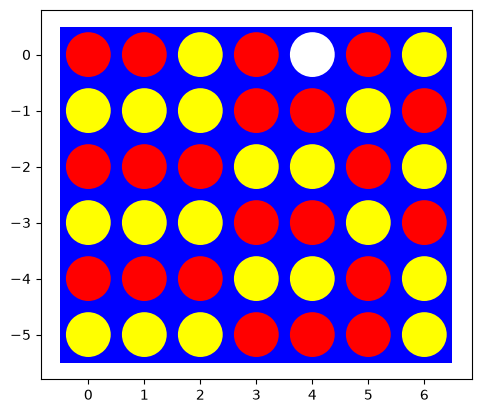

In [17]:
def trace_agent(agent, label, records):
    def act(board, player=1):
        move = agent.act(board, player)
        records.append({
            "Tác tử": label,
            "Quân": player,
            "Cột": move,
            "Thời gian (s)": agent.last_search["seconds"],
        })
        return move
    return act


depth2_agent = MinimaxAgent(ordering=True, memo=True, cutoff=2, time_limit=60)
depth4_agent = MinimaxAgent(ordering=True, memo=True, cutoff=4, time_limit=60)
heuristic_game_trace = []
heuristic_game_outcome = play_game(
    trace_agent(depth2_agent, "Cutoff 2", heuristic_game_trace),
    trace_agent(depth4_agent, "Cutoff 4", heuristic_game_trace),
    shape=(6, 7),
)
heuristic_game_moves = [turn["Cột"] for turn in heuristic_game_trace]
heuristic_final_board = board_from_moves(heuristic_game_moves, (6, 7))
assert terminal(heuristic_final_board)
assert utility(heuristic_final_board, 1) == heuristic_game_outcome
heuristic_game_rows = []
for label, player in [("Cutoff 2", 1), ("Cutoff 4", -1)]:
    elapsed = [turn["Thời gian (s)"] for turn in heuristic_game_trace if turn["Tác tử"] == label]
    heuristic_game_rows.append({
        "Tác tử": label,
        "Quân": player,
        "Số lượt": len(elapsed),
        "Utility": heuristic_game_outcome * player,
        "TB/nước (ms)": 1000 * np.mean(elapsed),
    })
heuristic_game_table = pd.DataFrame(heuristic_game_rows)
display(heuristic_game_table.round({"TB/nước (ms)": 3}))
print("Chuỗi cột của ván đấu:", heuristic_game_moves)
visualize(heuristic_final_board)

Ván đấu trên 6×7 kết thúc sau 41 nước, cutoff 2 thắng. Cutoff 2 đi trước, cutoff 4 đi sau.

- Cutoff 2 cầm quân 1, đi 21 lượt, làm mốc so sánh thời gian trung bình mỗi nước.
- Cutoff 4 cầm quân -1, đi 20 lượt, chậm hơn cutoff 2 khoảng 6 lần mỗi nước.

Hai tác tử đều quyết định xác định nên cùng thế xuất phát, cấu hình và thứ tự duyệt sẽ lặp lại ván này. Kết quả cho biết hành vi của cặp cấu hình ở hai vai đã chọn. Một ván chưa đủ để xếp hạng độ sâu một cách tổng quát. Độ sâu lớn hơn vẫn phụ thuộc vào heuristic, thế cờ và vai đi trước.

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [18]:
class PureMonteCarloAgent:
    """Chọn cột có utility trung bình lớn nhất từ các ván mô phỏng ngẫu nhiên."""

    # Dùng lại bộ kiểm tra thắng bằng bit của Ngày 2; phương thức cần self.stride.
    _has_won = MinimaxAgent._has_won

    def __init__(self, playouts=100, seed=0, time_limit=60):
        self.playouts = index(playouts)
        if self.playouts < 1:
            raise ValueError("Playouts per legal action must be positive.")
        self.rng = np.random.default_rng(seed)
        self.time_limit = time_limit
        self.last_search = None

    def _playout(self, own, opponent, heights):
        if self._has_won(own):
            return 1
        heights = heights.copy()
        available = [col for col, height in enumerate(heights) if height < self.rows]
        bits = [own, opponent]
        # Chỉ số 0 là người ở gốc, 1 là đối thủ đi sau nước thử.
        turn = 1
        while available:
            col = available[int(self.rng.integers(len(available)))]
            bits[turn] |= 1 << (col * self.stride + heights[col])
            heights[col] += 1
            self.simulated_moves += 1
            if self._has_won(bits[turn]):
                return 1 if turn == 0 else -1
            if heights[col] == self.rows:
                available.remove(col)
            turn = 1 - turn
        return 0

    def search(self, board, player=1):
        start = perf_counter()
        deadline = start + self.time_limit
        final_value = utility(board, player)
        self.rows = board.shape[0]
        self.stride = self.rows + 1
        self.simulated_moves = 0
        sampled, action_values = 0, []
        best_move, best_value, completed = None, final_value, True
        if final_value is None:
            own, opponent, heights = _board_bits(board, player)
            try:
                for col in actions(board):
                    bit = 1 << (col * self.stride + heights[col])
                    after_heights = heights.copy()
                    after_heights[col] += 1
                    total = 0
                    for _ in range(self.playouts):
                        if perf_counter() >= deadline:
                            raise SearchTimeout("Monte Carlo sampling exceeded its time limit.")
                        total += self._playout(own | bit, opponent, after_heights)
                        sampled += 1
                    mean = total / self.playouts
                    action_values.append({"column": col, "mean": mean, "playouts": self.playouts})
                    if best_move is None or mean > best_value:
                        best_move, best_value = col, mean
            except SearchTimeout:
                best_move, best_value, completed = None, None, False
        self.last_search = {
            "move": best_move,
            "value": best_value,
            "completed": completed,
            "playouts": sampled,
            "simulated_moves": self.simulated_moves,
            "action_values": action_values,
            "seconds": perf_counter() - start,
        }
        return self.last_search.copy()

    def act(self, board, player=1):
        answer = self.search(board, player)
        if not answer["completed"]:
            raise SearchTimeout("Sampling did not finish within the time limit.")
        if answer["move"] is None:
            raise ValueError("There is no move on a terminal board.")
        return answer["move"]


# Bàn 1×1 luôn hòa sau nước đầu; kiểm tra thêm utility theo góc nhìn quân -1.
small = empty_board((1, 1))
small_copy = small.copy()
smoke = PureMonteCarloAgent(playouts=3, seed=52).search(small)
assert smoke["completed"] and smoke["move"] == 0 and smoke["value"] == 0
assert smoke["playouts"] == 3 and np.array_equal(small, small_copy)
terminal_board = board_from_moves([0, 1, 0, 1, 0, 2, 0], (6, 7))
terminal_answer = PureMonteCarloAgent(playouts=3).search(terminal_board, -1)
assert terminal_answer["move"] is None and terminal_answer["value"] == -1
assert terminal_answer["playouts"] == 0
print("Kiểm tra PMCS trên bàn nhỏ, bàn kết thúc và tính bất biến của bàn đầu vào · đạt")

Kiểm tra PMCS trên bàn nhỏ, bàn kết thúc và tính bất biến của bàn đầu vào · đạt


Mỗi cột hợp lệ được đánh giá bằng cùng số N playout. Sau nước thử ở gốc, hai bên chọn đều trong các cột chưa đầy cho tới khi có người thắng hoặc bàn đầy. Utility được tính theo người đang chọn nước ở gốc. Agent chọn cột có trung bình utility lớn nhất, giữ cột xuất hiện trước nếu bằng điểm.

Thuật toán dùng lại cách đổi bàn NumPy thành bit và kiểm tra thắng của Ngày 2 để mô phỏng nhanh. Mỗi playout sao chép chiều cao cột, nên bàn đầu vào giữ nguyên. Một nước thắng ngay có utility 1 ở tất cả các mẫu của cột đó. Các cột khác vẫn được đánh giá bằng playout ngẫu nhiên. PMCS không dùng heuristic hay bước tìm kiếm Minimax.

N là số mẫu cho mỗi cột, tổng số mẫu là N nhân số cột hợp lệ. RNG nằm trong instance với seed xác định cho từng thí nghiệm. Khi lấy mẫu chạm giới hạn 60 giây, agent báo chưa hoàn tất và không trả quyết định từ bảng mẫu dở dang.

Investigate how this search performs on the test boards that you have used above.

In [19]:
# N là số playout cho MỖI cột hợp lệ; mỗi dòng dùng một instance mới.
monte_test_rows = []
for position_index, (name, moves) in enumerate(standard_positions):
    board = board_from_moves(moves, (6, 7))
    player = (-1) ** len(moves)
    for count in (20, 100, 500):
        saved_board = board.copy()
        agent = PureMonteCarloAgent(playouts=count, seed=5400 + position_index)
        answer = agent.search(board, player)
        assert answer["completed"] and answer["move"] in actions(board)
        assert -1 <= answer["value"] <= 1 and np.array_equal(board, saved_board)
        assert answer["playouts"] == count * len(actions(board))
        goal = answer["move"] in tactical_moves[name] if name in tactical_moves else None
        monte_test_rows.append({
            "Bàn 6×7": name,
            "N/cột": count,
            "Cột": answer["move"],
            "Điểm MC": answer["value"],
            "Đúng mục tiêu chiến thuật": goal,
            "Số playout": answer["playouts"],
            "Thời gian (s)": answer["seconds"],
        })
monte_test_table = pd.DataFrame(monte_test_rows)
display(monte_test_table.round({"Điểm MC": 4, "Thời gian (s)": 6}))

# Đối đầu 100 ván trên 6×7, chia đều hai vai. Cache heuristic mới cho mỗi ván.
# Hai thuật toán dùng cấu hình cố định; thời gian thực tế được ghi riêng.
comparison_match_rows = []
for monte_side in (1, -1):
    totals = {1: 0, -1: 0, 0: 0}
    elapsed_monte, elapsed_heuristic = [], []
    for game in range(50):
        monte_agent = PureMonteCarloAgent(playouts=100, seed=54000 + 1000 * monte_side + game)
        heuristic_agent = MinimaxAgent(ordering=True, memo=True, cutoff=4, time_limit=60)
        trace = []
        monte_act = trace_agent(monte_agent, "PMCS N=100/cột", trace)
        heuristic_act = trace_agent(heuristic_agent, "Heuristic cutoff=4", trace)
        if monte_side == 1:
            outcome = play_game(monte_act, heuristic_act, shape=(6, 7))
        else:
            outcome = play_game(heuristic_act, monte_act, shape=(6, 7))
        totals[outcome * monte_side] += 1
        elapsed_monte.extend(turn["Thời gian (s)"] for turn in trace if turn["Tác tử"] == "PMCS N=100/cột")
        elapsed_heuristic.extend(turn["Thời gian (s)"] for turn in trace if turn["Tác tử"] == "Heuristic cutoff=4")
        if (game + 1) % 10 == 0:
            print(f"PMCS quân {monte_side} · xong {game + 1}/50 ván", flush=True)
    assert sum(totals.values()) == 50
    comparison_match_rows.append({
        "Quân PMCS": monte_side,
        "Số ván": 50,
        "PMCS thắng": totals[1],
        "Hòa": totals[0],
        "Heuristic thắng": totals[-1],
        "PMCS TB/nước (ms)": 1000 * np.mean(elapsed_monte),
        "Heuristic TB/nước (ms)": 1000 * np.mean(elapsed_heuristic),
    })
comparison_match_table = pd.DataFrame(comparison_match_rows)
assert comparison_match_table["Số ván"].sum() == 100
display(comparison_match_table.round({"PMCS TB/nước (ms)": 3, "Heuristic TB/nước (ms)": 3}))

,Bàn 6×7,N/cột,Cột,Điểm MC,Đúng mục tiêu chiến thuật,Số playout,Thời gian (s)
0,Màu 1 thắng ngay,20,0,1.000,True,140,0.005951
1,Màu 1 thắng ngay,100,0,1.000,True,700,0.024580
2,Màu 1 thắng ngay,500,0,1.000,True,3500,0.196119
3,Màu -1 thắng ngay,20,1,1.000,True,140,0.005210
4,Màu -1 thắng ngay,100,1,1.000,True,700,0.023965
5,Màu -1 thắng ngay,500,1,1.000,True,3500,0.144697
6,Phải chặn cột 1,20,0,0.100,False,140,0.006107
7,Phải chặn cột 1,100,1,0.240,True,700,0.028067
8,Phải chặn cột 1,500,1,0.118,True,3500,0.139388
9,Chuỗi từ bàn hòa 4×4,20,1,0.500,None,140,0.005603


PMCS quân 1 · xong 10/50 ván


PMCS quân 1 · xong 20/50 ván


PMCS quân 1 · xong 30/50 ván


PMCS quân 1 · xong 40/50 ván


PMCS quân 1 · xong 50/50 ván


... (2 outputs left out)

PMCS quân -1 · xong 30/50 ván


PMCS quân -1 · xong 40/50 ván


PMCS quân -1 · xong 50/50 ván


,Quân PMCS,Số ván,PMCS thắng,Hòa,Heuristic thắng,PMCS TB/nước (ms),Heuristic TB/nước (ms)
0,1,50,0,1,49,27.407,3.074
1,-1,50,6,1,43,25.821,2.384


- N=20/cột đáp ứng mục tiêu chiến thuật ở 3/4 bàn có cột thắng ngay hoặc cột phải chặn trong mẫu chạy này.
- N=100/cột đáp ứng mục tiêu chiến thuật ở 4/4 bàn có cột thắng ngay hoặc cột phải chặn trong mẫu chạy này.
- N=500/cột đáp ứng mục tiêu chiến thuật ở 4/4 bàn có cột thắng ngay hoặc cột phải chặn trong mẫu chạy này.

Tất cả nước chọn đều hợp lệ, điểm MC nằm trong [-1, 1] và bàn đầu vào giữ nguyên. Hai bàn có tên bắt đầu bằng “Chuỗi từ” không có nhãn mục tiêu chiến thuật hoặc giá trị đầy đủ trên 6×7, nên cột đánh giá ở đó để trống.

Mỗi dòng là một lần chạy với seed xác định theo chỉ số bàn. Tăng N tăng số mẫu và thời gian, giúp ước lượng trung bình có cơ hội ổn định hơn. Một lần chạy ở mỗi N chưa đo được độ biến động giữa nhiều seed. Ngay cả khi N lớn, playout ngẫu nhiên vẫn đánh giá kết quả trước các nước ngẫu nhiên của đối thủ, nên có thể bỏ qua một phản công mà đối thủ mạnh sẽ chủ động chọn.

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

Trên 100 ván 6×7, chia 50 ván cho mỗi vai của PMCS, PMCS thắng 6, heuristic thắng 92, hòa 2. Heuristic cutoff 4 thắng nhiều ván hơn PMCS N=100/cột trong mẫu này.

- Khi PMCS cầm quân 1, PMCS thắng 0, hòa 1, heuristic thắng 49. PMCS chậm hơn heuristic khoảng 9 lần mỗi nước.
- Khi PMCS cầm quân -1, PMCS thắng 6, hòa 1, heuristic thắng 43. PMCS chậm hơn heuristic khoảng 11 lần mỗi nước.

Đây là so sánh với N và cutoff cố định, có tỉ lệ thời gian đo được đi kèm. Hai cấu hình không được điều chỉnh cho cùng ngân sách thời gian. Cache heuristic bắt đầu trống mỗi ván và được tái sử dụng giữa các lượt trong ván. PMCS có seed riêng cho từng ván và lấy mẫu lại khi chọn nước.

Heuristic tận dụng kiến thức về các cửa sổ bốn ô để hướng tìm kiếm, còn Alpha-Beta xét phản ứng mạnh của đối thủ trong độ sâu cutoff. PMCS đánh giá mỗi nước bằng nhiều ván ngẫu nhiên và không cần thiết kế trọng số đánh giá thủ công. Chất lượng của hai cách phụ thuộc độ sâu, số playout, tính phù hợp của heuristic, chiến thuật mô phỏng, giai đoạn ván và thời gian cho phép. N lớn hơn làm ước lượng trước đối thủ ngẫu nhiên ổn định hơn, nhưng không biến nó thành giá trị Minimax khi đối thủ chơi tối ưu.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

In [ ]:
# Your code/ answer goes here.

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

In [ ]:
# Your code/ answer goes here.

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [ ]:
# Your code/ answer goes here.